# Capítulo 5 · Vecinos más cercanos: clasificar y predecir un número

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/lectures/chapter_05/06_knn_clasificacion_y_regresion.ipynb)

**Aprendizaje supervisado · Uso de KNN**

KNN no ajusta una fórmula. Para un dato nuevo busca los `k` puntos de entrenamiento más cercanos y contesta con ellos:

- **Clasificación:** la clase que más se repite entre esos vecinos.
- **Regresión:** el promedio de su valor.

La cercanía se mide con los números tal cual. Si una columna va por miles y otra por decenas, la grande decide sola quién es vecino. Por eso, antes de KNN, se estandariza. A un árbol no le pasa: solo compara cada variable con un umbral.

`k=1` copia el vecino más cercano y memoriza el entrenamiento. Un `k` más grande suaviza la respuesta.

### 📚 Índice
1. Iris: un vistazo y clasificar
2. Autos: un vistazo y predecir millas por galón
3. Chuleta resumen


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
palette = sns.color_palette("deep")

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = raiz / "data"


---
## 1. Iris: un vistazo y clasificar

Las mismas 150 flores de la lectura del árbol: 4 medidas en centímetros y 3 especies.


In [2]:
iris = pd.read_csv(DATA_DIR / "iris.csv")
especies = ["setosa", "versicolor", "virginica"]
iris.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Cómo se ve

50 flores de cada especie. En el pétalo, la setosa queda aparte; las otras dos se acercan. Quien esté cerca en ese gráfico suele ser de la misma especie: de eso se agarra KNN.


In [3]:
iris["target"].map(dict(enumerate(especies))).value_counts().rename("flores")


target
setosa        50
versicolor    50
virginica     50
Name: flores, dtype: int64

In [4]:
iris.drop(columns="target").describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


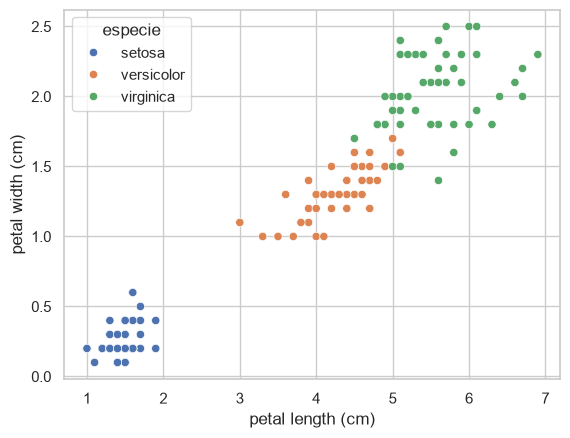

In [5]:
iris_plot = iris.assign(especie=iris["target"].map(dict(enumerate(especies))))
sns.scatterplot(
    data=iris_plot, x="petal length (cm)", y="petal width (cm)",
    hue="especie", palette=palette[:3]
)
plt.show()


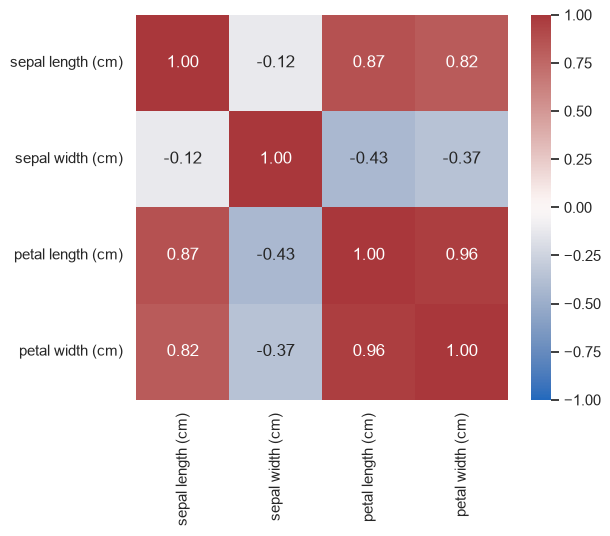

In [6]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    iris.drop(columns="target").corr(), annot=True, fmt=".2f",
    cmap="vlag", center=0, vmin=-1, vmax=1
)
plt.show()


El `Pipeline` estandariza y luego busca vecinos. `n_neighbors` es la `k`.

No se elige mirando el test. Para cada `k` se mide la accuracy con validación cruzada y se grafica. El mejor `k` es el pico de esa curva; el test se evalúa una sola vez, con ese valor. Con `k=1` la accuracy de train es 1: cada flor es su propio vecino.


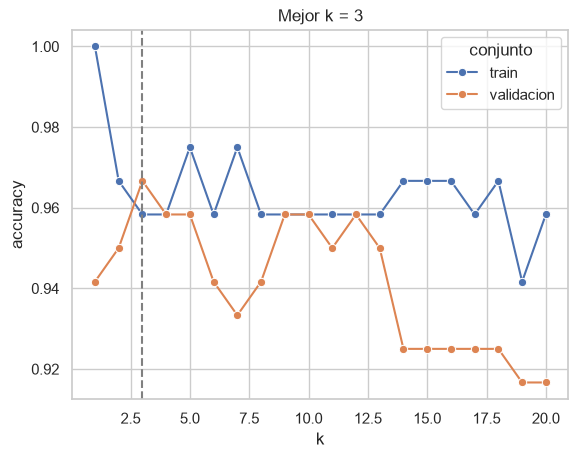

k elegido: 3
Accuracy test: 0.933


In [7]:
X = iris.drop(columns="target")
y = iris["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

filas = []
for k in range(1, 21):
    modelo = Pipeline([
        ("escala", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    modelo.fit(X_train, y_train)
    filas.append({
        "k": k,
        "train": modelo.score(X_train, y_train),
        "validacion": cross_val_score(modelo, X_train, y_train, cv=cv, scoring="accuracy").mean(),
    })

curva = pd.DataFrame(filas)
mejor_k = int(curva.loc[curva["validacion"].idxmax(), "k"])

sns.lineplot(data=curva.melt(id_vars="k", var_name="conjunto", value_name="accuracy"),
             x="k", y="accuracy", hue="conjunto", marker="o")
plt.axvline(mejor_k, color="gray", linestyle="--")
plt.title(f"Mejor k = {mejor_k}")
plt.show()

elegido = Pipeline([
    ("escala", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=mejor_k)),
])
elegido.fit(X_train, y_train)
print(f"k elegido: {mejor_k}")
print(f"Accuracy test: {elegido.score(X_test, y_test):.3f}")


En iris las cuatro medidas ya están en centímetros, así que escalar cambia poco. El efecto grande de la escala se ve en los autos, donde el peso va por miles y el año va de 70 a 82.


---
## 2. Autos: un vistazo y predecir millas por galón

Mismos autos que en el árbol. El regresor promedia el `mpg` de los `k` vecinos.


### Cómo se ve

398 autos y 6 sin `horsepower`. A más peso, menos millas por galón.


In [8]:
autos = pd.read_csv(DATA_DIR / "mpg.csv")
autos.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [9]:
autos.isna().sum().rename("nulos")


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
Name: nulos, dtype: int64

In [10]:
autos.describe()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


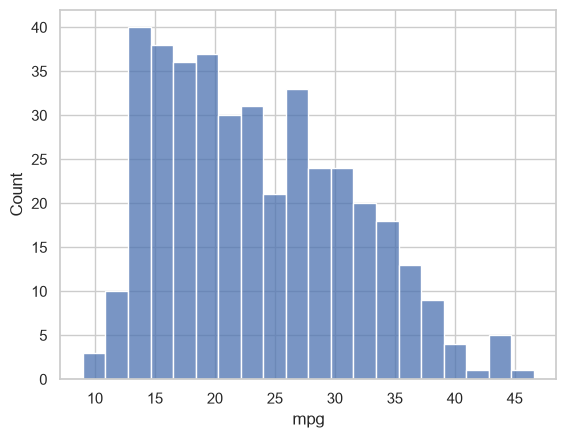

In [11]:
sns.histplot(data=autos, x="mpg", bins=20, color=palette[0])
plt.show()


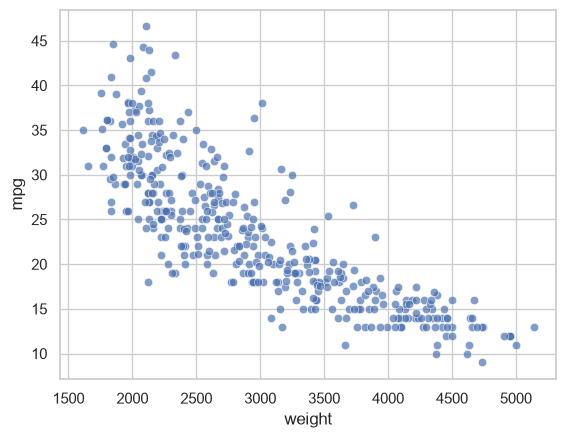

In [12]:
sns.scatterplot(data=autos, x="weight", y="mpg", color=palette[0], alpha=0.7)
plt.show()


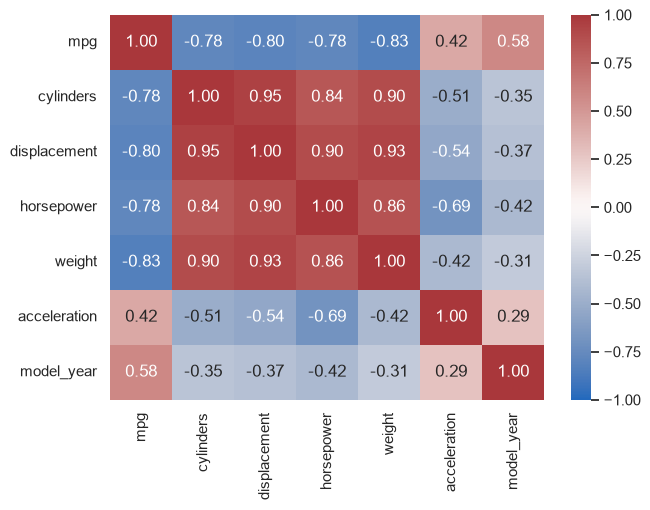

In [13]:
plt.figure(figsize=(7, 5))
sns.heatmap(autos.corr(numeric_only=True), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.show()


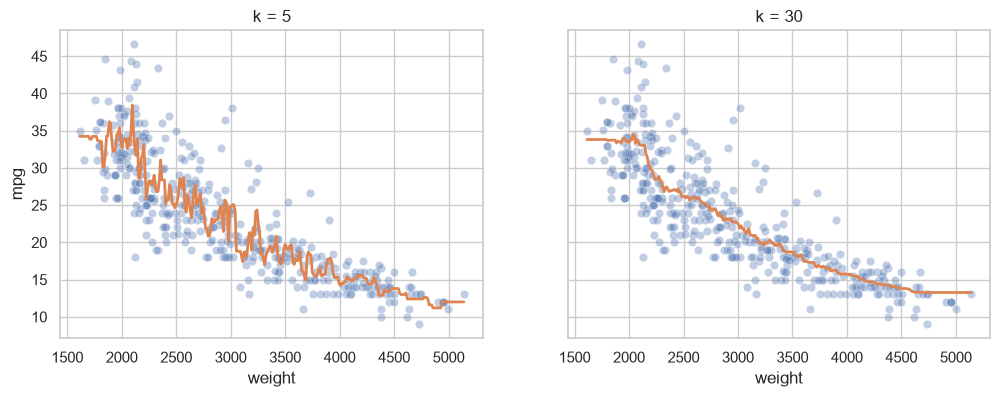

In [14]:
autos = autos.dropna()
X_peso = autos[["weight"]]
y_mpg = autos["mpg"]
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_peso, y_mpg, test_size=0.2, random_state=42
)

pesos = np.linspace(autos["weight"].min(), autos["weight"].max(), 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, k in zip(axes, [5, 30]):
    modelo = KNeighborsRegressor(n_neighbors=k)
    modelo.fit(X_train_p, y_train_p)
    curva = modelo.predict(pd.DataFrame({"weight": pesos}))
    sns.scatterplot(data=autos, x="weight", y="mpg", color=palette[0], alpha=0.35, ax=ax)
    ax.plot(pesos, curva, color=palette[1], linewidth=2)
    ax.set_title(f"k = {k}")
plt.show()


Con peso, potencia y año, sin escalar, el peso manda. La misma `k=5` con `StandardScaler` deja que las tres columnas cuenten parecido.


In [15]:
columnas = ["weight", "horsepower", "model_year"]
X_auto = autos[columnas]
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_auto, y_mpg, test_size=0.2, random_state=42
)

filas = []
for nombre, pasos in {
    "sin escalar": [("knn", KNeighborsRegressor(n_neighbors=5))],
    "escalado": [("escala", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=5))],
}.items():
    modelo = Pipeline(pasos)
    modelo.fit(X_train_a, y_train_a)
    pred = modelo.predict(X_test_a)
    filas.append({
        "modelo": nombre,
        "R2_test": modelo.score(X_test_a, y_test_a),
        "RMSE_test": root_mean_squared_error(y_test_a, pred),
    })

pd.DataFrame(filas).round(3)


,modelo,R2_test,RMSE_test
0,sin escalar,0.703,3.892
1,escalado,0.872,2.558


Con los datos ya escalados se repite la curva, ahora con $R^2$. `k=1` memoriza el train. El `k` se elige por el pico de validación, no por el test.


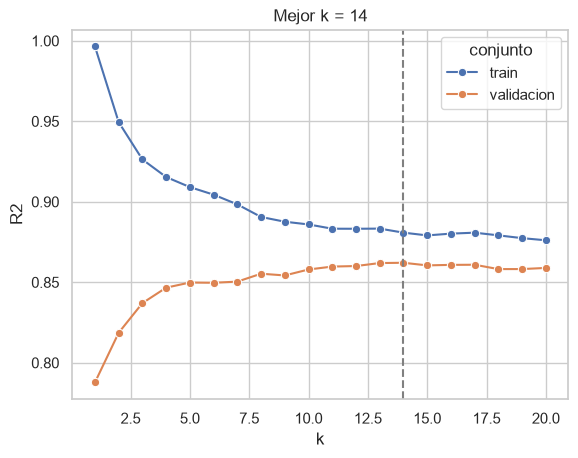

k elegido: 14
R² test:   0.874
RMSE test: 2.536


In [16]:
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)
filas = []
for k in range(1, 21):
    modelo = Pipeline([
        ("escala", StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=k)),
    ])
    modelo.fit(X_train_a, y_train_a)
    filas.append({
        "k": k,
        "train": modelo.score(X_train_a, y_train_a),
        "validacion": cross_val_score(modelo, X_train_a, y_train_a, cv=cv_reg, scoring="r2").mean(),
    })

curva = pd.DataFrame(filas)
mejor_k = int(curva.loc[curva["validacion"].idxmax(), "k"])

sns.lineplot(data=curva.melt(id_vars="k", var_name="conjunto", value_name="R2"),
             x="k", y="R2", hue="conjunto", marker="o")
plt.axvline(mejor_k, color="gray", linestyle="--")
plt.title(f"Mejor k = {mejor_k}")
plt.show()

elegido = Pipeline([
    ("escala", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=mejor_k)),
])
elegido.fit(X_train_a, y_train_a)
pred = elegido.predict(X_test_a)
print(f"k elegido: {mejor_k}")
print(f"R² test:   {elegido.score(X_test_a, y_test_a):.3f}")
print(f"RMSE test: {root_mean_squared_error(y_test_a, pred):.3f}")


---
## 3. 📋 Chuleta resumen

| Tarea | Código |
|---|---|
| Clasificar | `KNeighborsClassifier(n_neighbors=5)` |
| Predecir un número | `KNeighborsRegressor(n_neighbors=5)` |
| Estandarizar y luego el modelo | `Pipeline([("escala", StandardScaler()), ("knn", ...)])` |
| Elegir `k` | accuracy de `cross_val_score` para cada `k`; el pico es el elegido |
| Entrenar y predecir | `.fit(X_train, y_train)`, `.predict(X_test)` |
| Train y test, clasificación | `train_test_split(..., stratify=y, random_state=42)` |
| Train y test, regresión | `train_test_split(..., random_state=42)` sin `stratify` |

> 💡 `k=1` memoriza. Si las columnas no comparten escala, KNN sin `StandardScaler` ignora las chicas.
